# Cairo Governorate as precision-5 geohash cells

Question: how many precision-5 geohash cells (about 5 km wide) are needed to cover Cairo Governorate, and how much of each border cell is really inside?

Data: Cairo Governorate boundary, (c) OpenStreetMap contributors, ODbL 1.0 (`data/cairo_governorate.geojson`). Coordinates are WGS84 lon/lat (x=lon, y=lat); areas are geodesic on the WGS84 ellipsoid. Run this notebook from the `showcase/` folder.

In [1]:
import sys
sys.path.insert(0, '../src')  # use the repository checkout
import geohash_kit as gk
from pyproj import Geod
from shapely.geometry import box

GEOD = Geod(ellps='WGS84')
def area_km2(g):
    return abs(GEOD.geometry_area_perimeter(g)[0]) / 1e6

## 1. Load the boundary

In [2]:
boundary = gk.read_geometry('data/cairo_governorate.geojson')
print(boundary.geom_type, 'bounds (min_lon, min_lat, max_lon, max_lat):', boundary.bounds)
print(f'geodesic area: {area_km2(boundary):.1f} km2')

Polygon bounds (min_lon, min_lat, max_lon, max_lat): (31.214555, 29.7483062, 31.9090054, 30.3209168)
geodesic area: 3007.5 km2


## 2. Cover it with geohash cells

`cover(..., 'intersects')` returns every cell touching the boundary; `'within'` only cells fully inside.

In [3]:
touching = gk.cover(boundary, 5)
inside = set(gk.cover(boundary, 5, 'within'))
print(len(touching), 'cells touch the boundary,', len(inside), 'are fully inside')

176 cells touch the boundary, 117 are fully inside


## 3. Inspect the result

For each cell: ellipsoidal area and the share of it inside the boundary.

In [4]:
rows = []
for code in touching:
    cell = box(*gk.decode_bbox(code))
    a = gk.cell_area_km2(code)
    got = a if code in inside else min(area_km2(cell.intersection(boundary)), a)
    rows.append({'geohash': code, 'kind': 'inside' if code in inside else 'edge',
                 'cell_km2': a, 'inside_km2': got, 'share_inside': got / a, 'geometry': cell})
print(f"{'geohash':8}{'kind':8}{'cell_km2':>10}{'inside_km2':>12}{'share':>8}")
for r in sorted(rows, key=lambda r: r['share_inside'])[:8]:
    print(f"{r['geohash']:8}{r['kind']:8}{r['cell_km2']:10.2f}{r['inside_km2']:12.2f}{r['share_inside']:8.3f}")
for k in ('inside', 'edge'):
    sel = [r for r in rows if r['kind'] == k]
    print(k, len(sel), 'cells', round(sum(r['cell_km2'] for r in sel), 1), 'km2')

geohash kind      cell_km2  inside_km2   share
stq9h   edge         20.71        0.03   0.002
stqdy   edge         20.65        0.04   0.002
stq9n   edge         20.71        0.06   0.003
stq1r   edge         20.70        0.06   0.003
stqs6   edge         20.59        0.17   0.008
stq79   edge         20.62        0.33   0.016
stq1z   edge         20.68        0.63   0.030
stq9j   edge         20.71        0.73   0.035
inside 117 cells 2417.1 km2
edge 59 cells 1218.7 km2


In [5]:
cover_km2 = sum(r['cell_km2'] for r in rows)
print(f'cover {cover_km2:.0f} km2 vs boundary {area_km2(boundary):.0f} km2 ({100 * (cover_km2 / area_km2(boundary) - 1):.1f}% larger)')
tahrir = gk.encode(30.0444, 31.2357, 5)  # Tahrir Square (lat, lon)
print('Tahrir Square cell:', tahrir, 'neighbours:', sorted(gk.neighbours(tahrir).values()))

cover 3636 km2 vs boundary 3007 km2 (20.9% larger)
Tahrir Square cell: stq4y neighbours: ['stq4t', 'stq4v', 'stq4w', 'stq4x', 'stq4z', 'stq5j', 'stq5n', 'stq5p']


## 4. Map

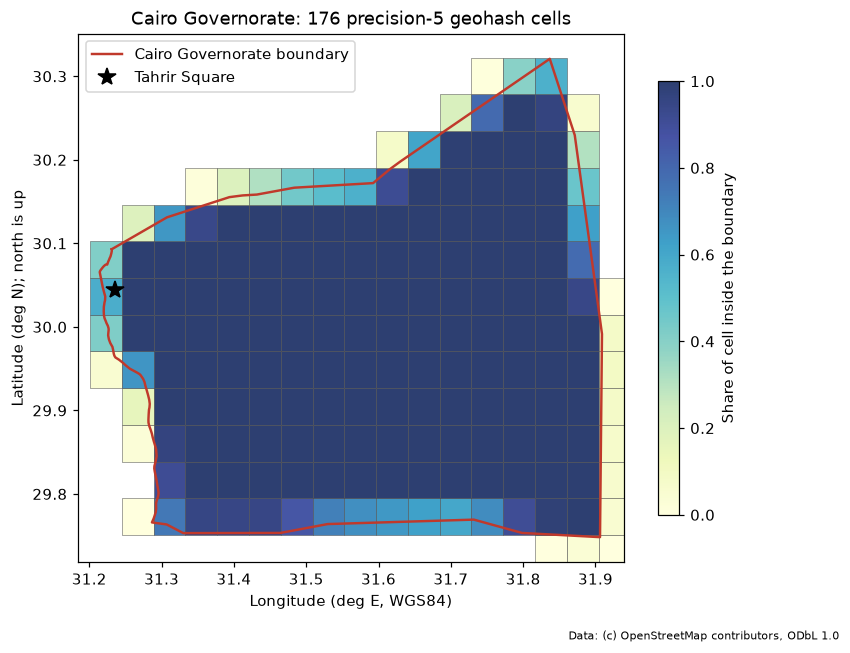

In [6]:
import math
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon

fig, ax = plt.subplots(figsize=(8, 6.4), dpi=110)
pc = PatchCollection([MplPolygon(list(r['geometry'].exterior.coords)) for r in rows],
                     cmap='YlGnBu', edgecolor='#555', linewidth=0.4, alpha=0.85)
pc.set_array([r['share_inside'] for r in rows]); pc.set_clim(0, 1); ax.add_collection(pc)
x, y = boundary.exterior.xy
ax.plot(x, y, color='#c0392b', lw=1.6, label='Cairo Governorate boundary')
ax.plot(31.2357, 30.0444, '*', color='black', ms=12, label='Tahrir Square')
minx, miny, maxx, maxy = boundary.bounds
ax.set_xlim(minx - 0.03, maxx + 0.03); ax.set_ylim(miny - 0.03, maxy + 0.03)
ax.set_aspect(1 / math.cos(math.radians((miny + maxy) / 2)))
ax.set_xlabel('Longitude (deg E, WGS84)'); ax.set_ylabel('Latitude (deg N); north is up')
ax.set_title(f'Cairo Governorate: {len(rows)} precision-5 geohash cells'); ax.legend(loc='upper left')
fig.colorbar(pc, ax=ax, shrink=0.8, label='Share of cell inside the boundary')
fig.text(0.99, 0.01, 'Data: (c) OpenStreetMap contributors, ODbL 1.0', ha='right', fontsize=7)
plt.show()